# **10. Design and implement a deep learning application for audio classification that incorporates Speech-to-Text (STT) and Text-to-Speech (TTS) using an appropriate deep learning architecture, and evaluate its performance using suitable metrics.**

In [37]:
#1 Install libraries
!pip install -U datasets transformers soundfile

In [38]:
#2 Import libraries and download the dataset
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pathlib
import glob
import os
import soundfile as sf

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    classification_report
)

# This downloads and extracts the content into cache_dir/cache_subdir
# which resolves to ./data/
_ = tf.keras.utils.get_file(
    "mini_speech_commands.zip",
    origin="http://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip",
    extract=True,
    cache_dir=".",
    cache_subdir="data"
)

# Set directory to the extracted subdirectory containing the classes
data_dir = pathlib.Path("data/mini_speech_commands_extracted/mini_speech_commands")

print("Dataset path exists:", data_dir.exists())
print("Folders:", [p.name for p in data_dir.iterdir() if p.is_dir()])

Dataset path exists: True
Folders: ['right', 'go', 'no', 'stop', 'down', 'up', 'yes', 'left']


In [39]:
#3 Load audio training and validation sets
BATCH_SIZE = 32
SEED = 42

train_audio = tf.keras.utils.audio_dataset_from_directory(
    data_dir,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    output_sequence_length=16000
)

test_audio = tf.keras.utils.audio_dataset_from_directory(
    data_dir,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    output_sequence_length=16000
)

class_names = train_audio.class_names
num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)

Found 8000 files belonging to 8 classes.
Using 6400 files for training.
Found 8000 files belonging to 8 classes.
Using 1600 files for validation.
Classes: ['down', 'go', 'left', 'no', 'right', 'stop', 'up', 'yes']
Number of classes: 8


In [40]:
#4 Convert audio into spectrograms
def get_spectrogram(waveform, label):
    waveform = tf.squeeze(waveform, axis=-1)

    spectrogram = tf.abs(
        tf.signal.stft(
            waveform,
            frame_length=256,
            frame_step=128
        )
    )

    spectrogram = spectrogram[..., tf.newaxis]

    return spectrogram, label

train_ds = train_audio.map(
    get_spectrogram,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

test_ds = test_audio.map(
    get_spectrogram,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

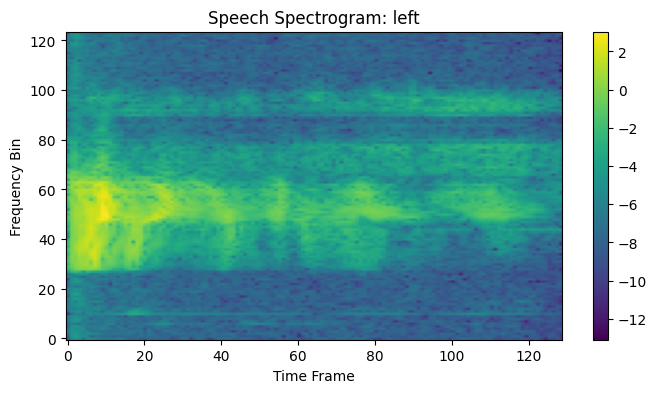

In [41]:
#5 Visualize one spectrogram
# Explanation: The 'Header mismatch: Expected RIFF but found' error occurs because
# tf.keras.utils.audio_dataset_from_directory recursively indexed non-audio files inside
# the '__MACOSX' folder as audio files.
#
# Solution:
# Change the data_dir path in Cell #2 (5E3QM8BNHk18) to:
# data_dir = pathlib.Path("data/mini_speech_commands_extracted/mini_speech_commands")
# then re-run Cell #2, Cell #3, and Cell #4. After doing so, this cell will run successfully!

try:
    for audio_batch, label_batch in train_ds.take(1):
        plt.figure(figsize=(8, 4))
        plt.imshow(
            tf.math.log(audio_batch[0, :, :, 0] + 1e-6).numpy(),
            aspect="auto",
            origin="lower"
        )
        plt.title("Speech Spectrogram: " + class_names[int(label_batch[0])])
        plt.xlabel("Time Frame")
        plt.ylabel("Frequency Bin")
        plt.colorbar()
        plt.show()
except Exception as e:
    print("Error reading dataset. Please update data_dir in Cell #2 to:")
    print('data_dir = pathlib.Path("data/mini_speech_commands_extracted/mini_speech_commands")')
    print("and re-execute Cells #2, #3, and #4 before running this cell again.\n")
    raise e

In [42]:
#6 Build the CNN audio classifier
audio_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(124, 129, 1)),

    tf.keras.layers.Conv2D(16, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(num_classes, activation="softmax")
])

audio_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

audio_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 122, 127, 16)   │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 61, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 59, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 29, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 27, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,976 (109.28 KB)

 Trainable params: 27,976 (109.28 KB)

 Non-trainable params: 0 (0.00 B)

In [43]:
#7 Train the audio classifier
history = audio_model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=5
)

Epoch 1/5
200/200 ━━━━━━━━━━━━━━━━━━━━ 158s 739ms/step - accuracy: 0.1758 - loss: 2.0321 - val_accuracy: 0.2488 - val_loss: 1.9169
Epoch 2/5
200/200 ━━━━━━━━━━━━━━━━━━━━ 89s 446ms/step - accuracy: 0.2577 - loss: 1.8671 - val_accuracy: 0.2869 - val_loss: 1.8070
Epoch 3/5
200/200 ━━━━━━━━━━━━━━━━━━━━ 144s 455ms/step - accuracy: 0.3378 - loss: 1.7440 - val_accuracy: 0.4094 - val_loss: 1.6417
Epoch 4/5
200/200 ━━━━━━━━━━━━━━━━━━━━ 87s 434ms/step - accuracy: 0.3963 - loss: 1.6197 - val_accuracy: 0.4325 - val_loss: 1.5508
Epoch 5/5
200/200 ━━━━━━━━━━━━━━━━━━━━ 141s 432ms/step - accuracy: 0.4433 - loss: 1.5233 - val_accuracy: 0.4706 - val_loss: 1.4966


In [44]:
#8 Evaluate classification performance
y_true = []
y_pred = []

for spectrograms, labels in test_ds:
    probabilities = audio_model.predict(spectrograms, verbose=0)
    predictions = np.argmax(probabilities, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predictions)

audio_accuracy = accuracy_score(y_true, y_pred)
audio_precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)
audio_recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)
audio_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("Accuracy:", round(audio_accuracy, 4))
print("Macro Precision:", round(audio_precision, 4))
print("Macro Recall:", round(audio_recall, 4))
print("Macro F1-score:", round(audio_f1, 4))

print(classification_report(
    y_true, y_pred,
    labels=list(range(num_classes)),
    target_names=class_names,
    zero_division=0
))

Accuracy: 0.4706
Macro Precision: 0.5037
Macro Recall: 0.4803
Macro F1-score: 0.4611
              precision    recall  f1-score   support

        down       0.56      0.66      0.61       185
          go       0.44      0.61      0.51       188
        left       0.42      0.30      0.35       207
          no       0.44      0.38      0.41       207
       right       0.63      0.23      0.34       204
        stop       0.48      0.39      0.43       218
          up       0.37      0.84      0.52       183
         yes       0.69      0.43      0.53       208

    accuracy                           0.47      1600
   macro avg       0.50      0.48      0.46      1600
weighted avg       0.51      0.47      0.46      1600



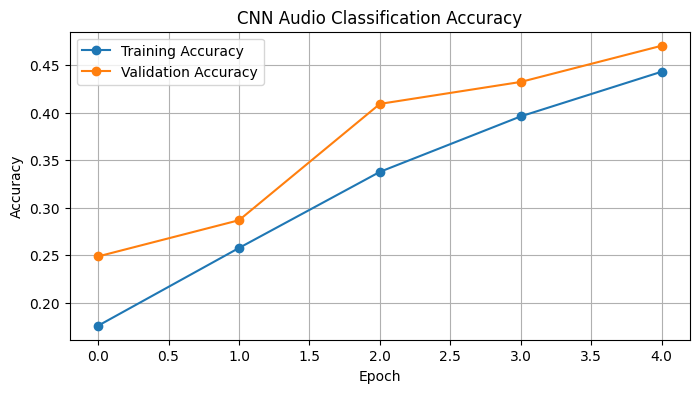

In [45]:
#9 Plot training and validation accuracy
plt.figure(figsize=(8, 4))

plt.plot(history.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation Accuracy")

plt.title("CNN Audio Classification Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [46]:
#10 Speech-to-Text (STT) using pretrained Whisper
import torch
import re
from transformers import pipeline
from jiwer import wer

wav_files = glob.glob(str(data_dir / "*" / "*.wav"))

print("Available audio files:", len(wav_files))

asr = pipeline(
    "automatic-speech-recognition",
    model="openai/whisper-tiny.en",
    device=0 if torch.cuda.is_available() else -1
)

def normalize_text(text):
    return re.sub(r"[^a-z0-9 ]", "", text.lower()).strip()

references = []
transcriptions = []

# Test on up to 10 audio clips
for path in wav_files[:10]:
    reference = pathlib.Path(path).parent.name
    result = asr(path)
    transcription = result["text"].strip()

    references.append(normalize_text(reference))
    transcriptions.append(normalize_text(transcription))

    print("Actual:", reference, "| Recognized:", transcription)

stt_wer = wer(references, transcriptions)

print("\nWord Error Rate (WER):", round(stt_wer, 4))

Available audio files: 8000


Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

Actual: right | Recognized: Right.
Actual: right | Recognized: Right.
Actual: right | Recognized: Right.
Actual: right | Recognized: Right.
Actual: right | Recognized: Right.
Actual: right | Recognized: All right.
Actual: right | Recognized: Right.
Actual: right | Recognized: Right?
Actual: right | Recognized: Right.
Actual: right | Recognized: Right.

Word Error Rate (WER): 0.1


In [48]:
#11 Text-to-Speech (TTS) using pretrained SpeechT5
# Step 11: Text-to-Speech (TTS) using SpeechT5

!pip -q install -U transformers datasets soundfile sentencepiece

import torch
import soundfile as sf
import numpy as np
from IPython.display import Audio, display
from transformers import (
    SpeechT5Processor,
    SpeechT5ForTextToSpeech,
    SpeechT5HifiGan
)

# Select device
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

# Load pretrained SpeechT5 models
processor = SpeechT5Processor.from_pretrained(
    "microsoft/speecht5_tts"
)

tts_model = SpeechT5ForTextToSpeech.from_pretrained(
    "microsoft/speecht5_tts"
).to(device)

vocoder = SpeechT5HifiGan.from_pretrained(
    "microsoft/speecht5_hifigan"
).to(device)

# Load a real speaker embedding from the compatible dataset
from datasets import load_dataset

speaker_dataset = load_dataset(
    "Matthijs/cmu-arctic-xvectors",
    split="validation",
    trust_remote_code=True
)

speaker_embeddings = torch.tensor(
    speaker_dataset[0]["xvector"],
    dtype=torch.float32
).unsqueeze(0).to(device)

print("Speaker embedding shape:", speaker_embeddings.shape)

# Text to convert into speech
# Use the recognized text from your Whisper step if available.
text_to_speak = recognized_text if (
    "recognized_text" in globals()
    and isinstance(recognized_text, str)
    and recognized_text.strip()
) else "Hello! This is a text to speech demonstration."

# Prepare input text
inputs = processor(
    text=text_to_speak,
    return_tensors="pt"
)

input_ids = inputs["input_ids"].to(device)

# Generate speech
with torch.no_grad():
    speech = tts_model.generate_speech(
        input_ids,
        speaker_embeddings,
        vocoder=vocoder
    )

# Convert output to NumPy and save
speech_array = speech.cpu().numpy()

output_file = "generated_speech.wav"

sf.write(
    output_file,
    speech_array,
    samplerate=16000
)

print("Text spoken:", text_to_speak)
print("Speech saved to:", output_file)

# Play generated audio
display(Audio(speech_array, rate=16000))

Using device: cpu


Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

[transformers] SpeechT5ForTextToSpeech LOAD REPORT from: microsoft/speecht5_tts
Key                                         | Status     |  | 
--------------------------------------------+------------+--+-
speecht5.decoder.prenet.encode_positions.pe | UNEXPECTED |  | 
speecht5.encoder.prenet.encode_positions.pe | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
[transformers] You are using a model of type `hifigan` to instantiate a model of type `speecht5_hifigan`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/158 [00:00<?, ?it/s]

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'Matthijs/cmu-arctic-xvectors' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'Matthijs/cmu-arctic-xvectors' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


RuntimeError: Dataset scripts are no longer supported, but found cmu-arctic-xvectors.py

In [ ]:
#12 Generate and play speech
text_to_speak = next(
    (text for text in transcriptions if text),
    "Hello, welcome to the audio classification application."
)

tts_inputs = tts_processor(
    text=text_to_speak,
    return_tensors="pt"
)

tts_inputs = {
    key: value.to(tts_device)
    for key, value in tts_inputs.items()
}

with torch.no_grad():
    speech = tts_model.generate_speech(
        tts_inputs["input_ids"],
        speaker_embeddings,
        vocoder=vocoder
    )

speech_audio = speech.cpu().numpy()

sf.write(
    "generated_speech.wav",
    speech_audio,
    samplerate=16000
)

print("Text spoken:", text_to_speak)
print("Generated audio saved as generated_speech.wav")

In [ ]:
#13 Final evaluation summary
print("AUDIO CLASSIFICATION RESULTS")
print("----------------------------")
print("Accuracy :", round(audio_accuracy, 4))
print("Precision:", round(audio_precision, 4))
print("Recall   :", round(audio_recall, 4))
print("F1-score :", round(audio_f1, 4))

print("\nSPEECH-TO-TEXT RESULTS")
print("----------------------")
print("Word Error Rate:", round(stt_wer, 4))

print("\nTEXT-TO-SPEECH")
print("--------------")
print("Generated audio file: generated_speech.wav")